In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
#import geobr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
#from cartopy.feature import NaturalEarthFeature
from cmcrameri import cm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

In [2]:
shapefile_path = os.path.join(
    "marajo_basin_shapefile",
    "marajo_basin.shp"
)

marajo = gpd.read_file(shapefile_path)

# Convert to geographic coordinates if necessary
if marajo.crs is None:
    raise ValueError("The shapefile has no CRS information.")

marajo = marajo.to_crs(epsg=4326)

print("Shapefile loaded successfully.")
print(f"CRS: {marajo.crs}")
print(f"Number of features: {len(marajo)}")
print(
    "Bounds [lon_min, lat_min, lon_max, lat_max]:",
    marajo.total_bounds
)

Shapefile loaded successfully.
CRS: EPSG:4326
Number of features: 1
Bounds [lon_min, lat_min, lon_max, lat_max]: [-51.2115  -5.6941 -46.832    1.1021]


In [3]:
data = np.loadtxt("marajo_data.xyz", skiprows=1, delimiter=",")

longitude = data[:, 0]
latitude = data[:, 1]
topography = data[:, 2]
etopo = data[:, 3]
gravity = data[:, 4]
anomaly = data[:, 5]
disturbance = data[:, 6]
bouguer = data[:, 7]
bouguer_correct = data[:, 8]
isostatic = data[:, 9]

n_points = data.shape[0]

# Determine the number of unique coordinates
lon_unique = np.unique(longitude)
lat_unique = np.unique(latitude)

n_lon = lon_unique.size
n_lat = lat_unique.size

print(f"Number of rows: {n_points}")
print(f"Unique longitudes: {n_lon}")
print(f"Unique latitudes:  {n_lat}")
print(f"Expected regular-grid size: {n_lat} x {n_lon}")
print(f"Expected number of points: {n_lat * n_lon}")

if n_lat * n_lon != n_points:
    raise ValueError("The number of rows is incompatible with a complete regular grid. "
                     "Check for missing points, duplicates, or irregular sampling.")
# Sort first by latitude and then by longitude before reshaping
order = np.lexsort((longitude, latitude))

lon_sorted = longitude[order]
lat_sorted = latitude[order]
topo_sorted = topography[order]
etopo_sorted = etopo[order]
gravity_sorted = gravity[order]
anomaly_sorted = anomaly[order]
disturbance_sorted = disturbance[order]
bouguer_sorted = bouguer[order]
bouguer_correct_sorted = bouguer_correct[order]
isostatic_sorted = isostatic[order]

LON = lon_sorted.reshape(n_lat, n_lon)
LAT = lat_sorted.reshape(n_lat, n_lon)
TOPO = topo_sorted.reshape(n_lat, n_lon)
ETOPO = etopo_sorted.reshape(n_lat, n_lon)
GRAV = gravity_sorted.reshape(n_lat, n_lon)
ANOM = anomaly_sorted.reshape(n_lat, n_lon)
DIST = disturbance_sorted.reshape(n_lat, n_lon)
BG = bouguer_sorted.reshape(n_lat, n_lon)
BGC = bouguer_correct_sorted.reshape(n_lat, n_lon)
ISO = isostatic_sorted.reshape(n_lat, n_lon)

Number of rows: 28341
Unique longitudes: 141
Unique latitudes:  201
Expected regular-grid size: 201 x 141
Expected number of points: 28341


In [4]:
estrutural_marajo = gpd.read_file(r"estrutural_marajo/estrutural_marajo.shp")

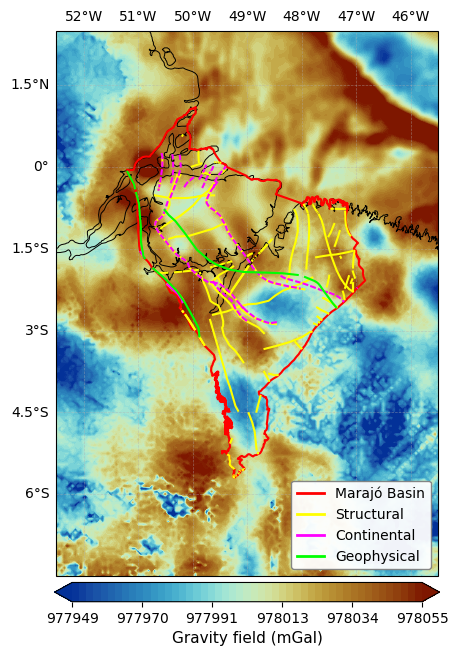

In [5]:
fig = plt.figure(figsize=(8,7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([LON.min(), LON.max(), LAT.min(), LAT.max()],crs=ccrs.PlateCarree())

vmin = np.nanpercentile(GRAV,2)
vmax = np.nanpercentile(GRAV,98)
levels = np.linspace(vmin,vmax,50)

cf = ax.contourf(LON,LAT,GRAV,levels=levels,cmap=cm.roma_r,extend="both",transform=ccrs.PlateCarree())

marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=10)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Structural"].plot(ax=ax,color="yellow",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Continental"].plot(ax=ax,color="magenta",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Geophysical"].plot(ax=ax,color="lime",linewidth=1.5,zorder=14)

ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False

ticks = np.linspace(vmin,vmax,6)
cbar = plt.colorbar(cf,ax=ax,orientation="horizontal",pad=0.01,shrink=0.50,ticks=ticks)
cbar.ax.set_xticklabels([f"{value:.0f}" for value in ticks])
cbar.set_label("Gravity field (mGal)",fontsize=11)

legend_handles = [Line2D([0],[0],color="red",linewidth=2.0,label="Marajó Basin"),
    Line2D([0],[0],color="yellow",linewidth=2.0,label="Structural"),
    Line2D([0],[0],color="magenta",linewidth=2.0,label="Continental"),
    Line2D([0],[0],color="lime",linewidth=2.0,label="Geophysical"),]

ax.legend(handles=legend_handles,loc="lower right",
          frameon=True,framealpha=0.95,facecolor="white",
          edgecolor="gray",fontsize=10)

plt.tight_layout()
plt.savefig("results/gravity.png",dpi=300,bbox_inches="tight")
plt.show()

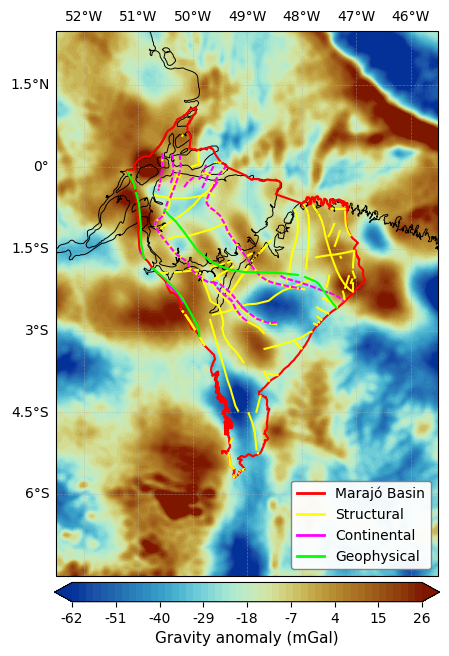

In [6]:
fig = plt.figure(figsize=(8,7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([LON.min(), LON.max(), LAT.min(), LAT.max()],crs=ccrs.PlateCarree())

vmin = np.nanpercentile(ANOM,2)
vmax = np.nanpercentile(ANOM,98)
levels = np.linspace(vmin,vmax,50)

cf = ax.contourf(LON,LAT,ANOM,levels=levels,cmap=cm.roma_r,extend="both",transform=ccrs.PlateCarree())

marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=10)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Structural"].plot(ax=ax,color="yellow",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Continental"].plot(ax=ax,color="magenta",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Geophysical"].plot(ax=ax,color="lime",linewidth=1.5,zorder=14)

ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False

ticks = np.linspace(vmin,vmax,9)
cbar = plt.colorbar(cf,ax=ax,orientation="horizontal",pad=0.01,shrink=0.50,ticks=ticks)
cbar.ax.set_xticklabels([f"{value:.0f}" for value in ticks])
cbar.set_label("Gravity anomaly (mGal)",fontsize=11)

legend_handles = [Line2D([0],[0],color="red",linewidth=2.0,label="Marajó Basin"),
    Line2D([0],[0],color="yellow",linewidth=2.0,label="Structural"),
    Line2D([0],[0],color="magenta",linewidth=2.0,label="Continental"),
    Line2D([0],[0],color="lime",linewidth=2.0,label="Geophysical"),]

ax.legend(handles=legend_handles,loc="lower right",
          frameon=True,framealpha=0.95,facecolor="white",
          edgecolor="gray",fontsize=10)

plt.tight_layout()
plt.savefig("results/anomaly.png",dpi=300,bbox_inches="tight")
plt.show()

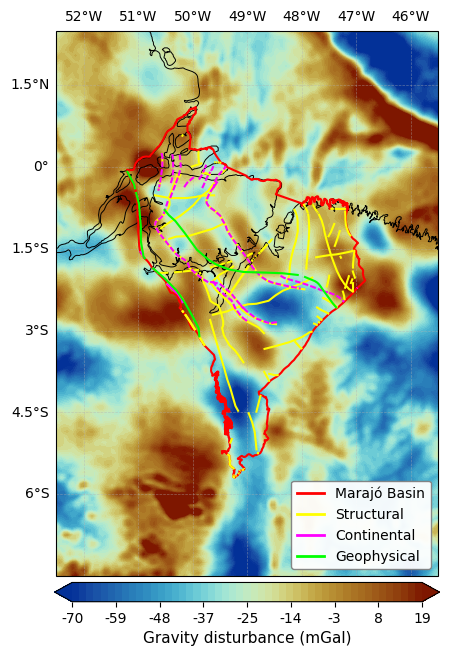

In [7]:
fig = plt.figure(figsize=(8,7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([LON.min(), LON.max(), LAT.min(), LAT.max()],crs=ccrs.PlateCarree())

vmin = np.nanpercentile(DIST,2)
vmax = np.nanpercentile(DIST,98)
levels = np.linspace(vmin,vmax,50)

cf = ax.contourf(LON,LAT,DIST,levels=levels,cmap=cm.roma_r,extend="both",transform=ccrs.PlateCarree())

marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=10)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Structural"].plot(ax=ax,color="yellow",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Continental"].plot(ax=ax,color="magenta",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Geophysical"].plot(ax=ax,color="lime",linewidth=1.5,zorder=14)

ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False

ticks = np.linspace(vmin,vmax,9)
cbar = plt.colorbar(cf,ax=ax,orientation="horizontal",pad=0.01,shrink=0.50,ticks=ticks)
cbar.ax.set_xticklabels([f"{value:.0f}" for value in ticks])
cbar.set_label("Gravity disturbance (mGal)",fontsize=11)

legend_handles = [Line2D([0],[0],color="red",linewidth=2.0,label="Marajó Basin"),
    Line2D([0],[0],color="yellow",linewidth=2.0,label="Structural"),
    Line2D([0],[0],color="magenta",linewidth=2.0,label="Continental"),
    Line2D([0],[0],color="lime",linewidth=2.0,label="Geophysical"),]

ax.legend(handles=legend_handles,loc="lower right",
          frameon=True,framealpha=0.95,facecolor="white",
          edgecolor="gray",fontsize=10)

plt.tight_layout()
plt.savefig("results/disturbance.png",dpi=300,bbox_inches="tight")
plt.show()

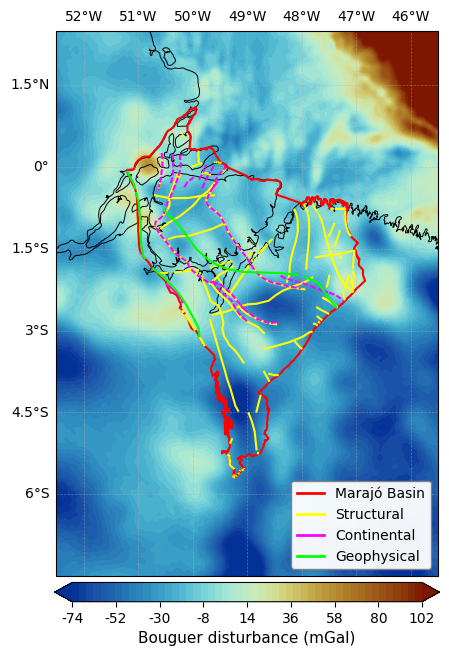

In [8]:
fig = plt.figure(figsize=(8,7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([LON.min(), LON.max(), LAT.min(), LAT.max()],crs=ccrs.PlateCarree())

vmin = np.nanpercentile(BG,2)
vmax = np.nanpercentile(BG,98)
levels = np.linspace(vmin,vmax,50)

cf = ax.contourf(LON,LAT,BG,levels=levels,cmap=cm.roma_r,extend="both",transform=ccrs.PlateCarree())

marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=10)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Structural"].plot(ax=ax,color="yellow",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Continental"].plot(ax=ax,color="magenta",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Geophysical"].plot(ax=ax,color="lime",linewidth=1.5,zorder=14)

ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False

ticks = np.linspace(vmin,vmax,9)
cbar = plt.colorbar(cf,ax=ax,orientation="horizontal",pad=0.01,shrink=0.50,ticks=ticks)
cbar.ax.set_xticklabels([f"{value:.0f}" for value in ticks])
cbar.set_label("Bouguer disturbance (mGal)",fontsize=11)

legend_handles = [Line2D([0],[0],color="red",linewidth=2.0,label="Marajó Basin"),
    Line2D([0],[0],color="yellow",linewidth=2.0,label="Structural"),
    Line2D([0],[0],color="magenta",linewidth=2.0,label="Continental"),
    Line2D([0],[0],color="lime",linewidth=2.0,label="Geophysical"),]

ax.legend(handles=legend_handles,loc="lower right",
          frameon=True,framealpha=0.95,facecolor="white",
          edgecolor="gray",fontsize=10)

plt.tight_layout()
plt.savefig("results/bouguer.png",dpi=300,bbox_inches="tight")
plt.show()

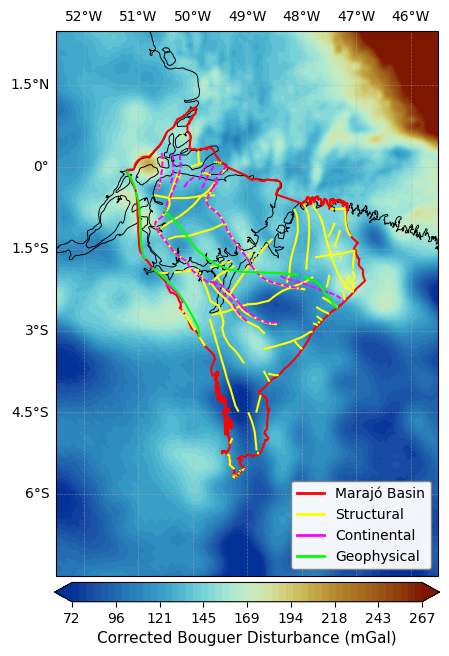

In [9]:
fig = plt.figure(figsize=(8,7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([LON.min(), LON.max(), LAT.min(), LAT.max()],crs=ccrs.PlateCarree())

vmin = np.nanpercentile(BGC,2)
vmax = np.nanpercentile(BGC,98)
levels = np.linspace(vmin,vmax,50)

cf = ax.contourf(LON,LAT,BGC,levels=levels,cmap=cm.roma_r,extend="both",transform=ccrs.PlateCarree())

marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=10)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Structural"].plot(ax=ax,color="yellow",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Continental"].plot(ax=ax,color="magenta",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Geophysical"].plot(ax=ax,color="lime",linewidth=1.5,zorder=14)

ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False

ticks = np.linspace(vmin,vmax,9)
cbar = plt.colorbar(cf,ax=ax,orientation="horizontal",pad=0.01,shrink=0.50,ticks=ticks)
cbar.ax.set_xticklabels([f"{value:.0f}" for value in ticks])
cbar.set_label("Corrected Bouguer Disturbance (mGal)",fontsize=11)

legend_handles = [Line2D([0],[0],color="red",linewidth=2.0,label="Marajó Basin"),
    Line2D([0],[0],color="yellow",linewidth=2.0,label="Structural"),
    Line2D([0],[0],color="magenta",linewidth=2.0,label="Continental"),
    Line2D([0],[0],color="lime",linewidth=2.0,label="Geophysical"),]

ax.legend(handles=legend_handles,loc="lower right",
          frameon=True,framealpha=0.95,facecolor="white",
          edgecolor="gray",fontsize=10)

plt.tight_layout()
plt.savefig("results/bouguer_corrected.png",dpi=300,bbox_inches="tight")
plt.show()

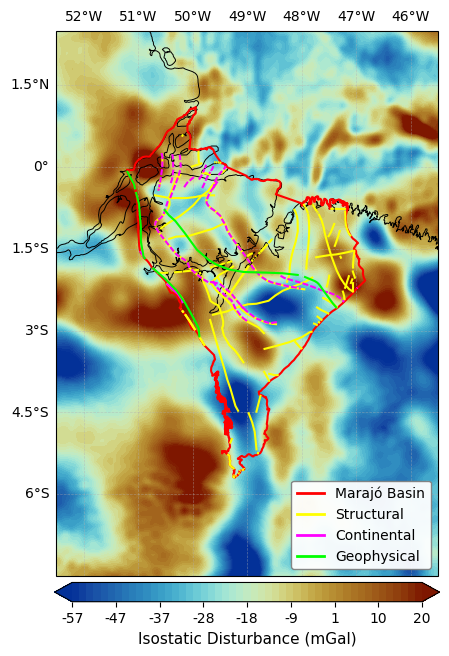

In [10]:
fig = plt.figure(figsize=(8,7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([LON.min(), LON.max(), LAT.min(), LAT.max()],crs=ccrs.PlateCarree())

vmin = np.nanpercentile(ISO,2)
vmax = np.nanpercentile(ISO,98)
levels = np.linspace(vmin,vmax,50)

cf = ax.contourf(LON,LAT,ISO,levels=levels,cmap=cm.roma_r,extend="both",transform=ccrs.PlateCarree())

marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=10)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Structural"].plot(ax=ax,color="yellow",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Continental"].plot(ax=ax,color="magenta",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Geophysical"].plot(ax=ax,color="lime",linewidth=1.5,zorder=14)

ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False

ticks = np.linspace(vmin,vmax,9)
cbar = plt.colorbar(cf,ax=ax,orientation="horizontal",pad=0.01,shrink=0.50,ticks=ticks)
cbar.ax.set_xticklabels([f"{value:.0f}" for value in ticks])
cbar.set_label("Isostatic Disturbance (mGal)",fontsize=11)

legend_handles = [Line2D([0],[0],color="red",linewidth=2.0,label="Marajó Basin"),
    Line2D([0],[0],color="yellow",linewidth=2.0,label="Structural"),
    Line2D([0],[0],color="magenta",linewidth=2.0,label="Continental"),
    Line2D([0],[0],color="lime",linewidth=2.0,label="Geophysical"),]

ax.legend(handles=legend_handles,loc="lower right",
          frameon=True,framealpha=0.95,facecolor="white",
          edgecolor="gray",fontsize=10)

plt.tight_layout()
plt.savefig("results/isostatic.png",dpi=300,bbox_inches="tight")
plt.show()

# Application to real data - Marajó basin

### (1) Preparing the grid for running gravity filters

In [11]:
from pyproj import Geod

In [12]:
geod = Geod(ellps="WGS84")

lon_axis = np.unique(longitude)
lat_axis = np.unique(latitude)

lon0 = np.mean(lon_axis)
lat0 = np.mean(lat_axis)

dlon = np.median(np.diff(lon_axis))
dlat = np.median(np.diff(lat_axis))

# Espaçamento E-W na latitude central
_, _, dx = geod.inv(
    lon0,
    lat0,
    lon0 + dlon,
    lat0
)

# Espaçamento N-S na longitude central
_, _, dy = geod.inv(
    lon0,
    lat0,
    lon0,
    lat0 + dlat
)

dx = abs(dx)
dy = abs(dy)

print(f"dx = {dx:.3f} m")
print(f"dy = {dy:.3f} m")
print(f"dx = {dx/1000:.3f} km")
print(f"dy = {dy/1000:.3f} km")

dx = 5560.712 m
dy = 5528.817 m
dx = 5.561 km
dy = 5.529 km


In [13]:
nx = len(np.unique(longitude))
ny = len(np.unique(latitude))

x = np.arange(nx) * dx
y = np.arange(ny) * dy

X, Y = np.meshgrid(x, y)

print(X.shape, Y.shape)
print(f"nx = {nx:.3f}")
print(f"ny = {ny:.3f}")
print(f"X: {X.min()/1000:.2f} a {X.max()/1000:.2f} km")
print(f"Y: {Y.min()/1000:.2f} a {Y.max()/1000:.2f} km")

(201, 141) (201, 141)
nx = 141.000
ny = 201.000
X: 0.00 a 778.50 km
Y: 0.00 a 1105.76 km


In [14]:
delta = max(dx, dy)

print(f"Delta = {delta:.3f} m")

Delta = 5560.712 m


In [15]:
heights = np.array([0.0,5.0 * delta,10.0 * delta,20.0 * delta])
print(heights, "(m)")
print(heights / 1000, "(km)")

[     0.          27803.56189292  55607.12378585 111214.2475717 ] (m)
[  0.          27.80356189  55.60712379 111.21424757] (km)


### (2) Importing gravity modules

In [16]:
import sys
import importlib

GRAVMAG_PARENT = os.environ.get("GRAVMAG_PARENT")

if GRAVMAG_PARENT and GRAVMAG_PARENT not in sys.path:
    sys.path.insert(0, GRAVMAG_PARENT)

from gravmag import filtering
from gravmag import derivative
from gravmag import grids
from gravmag import synthetic
from gravmag import prism

importlib.reload(derivative)
importlib.reload(filtering)
importlib.reload(grids)
importlib.reload(prism)
importlib.reload(synthetic)

<module 'gravmag.synthetic' from 'C:\\Users\\Usuario\\Python_Notebooks\\python\\geophysics\\gravmag\\synthetic.py'>

In [17]:
gx = derivative.my_xderiv(
    X,
    Y,
    ISO,
    n=1,
    pad_factor=0.5,
    pad_mode="reflect",
    taper=True,
    flatten=False
)

gy = derivative.my_yderiv(
    X,
    Y,
    ISO,
    n=1,
    pad_factor=0.5,
    pad_mode="reflect",
    taper=True,
    flatten=False
)

HGM = np.sqrt(gx**2 + gy**2)
HGM_km = HGM*1000.

print("gx:", gx.shape)
print("gy:", gy.shape)
print("HGM:", HGM.shape)

print(f"HGM min  = {np.nanmin(HGM):.6e}")
print(f"HGM max  = {np.nanmax(HGM):.6e}")
print(f"HGM mean = {np.nanmean(HGM):.6e}")
print(f"HGM std  = {np.nanstd(HGM):.6e}")

gx: (201, 141)
gy: (201, 141)
HGM: (201, 141)
HGM min  = 1.009854e-06
HGM max  = 3.815824e-03
HGM mean = 5.319683e-04
HGM std  = 3.623593e-04


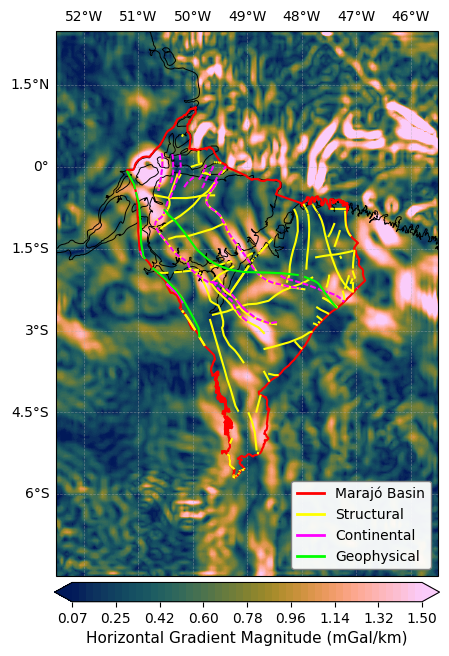

In [18]:
fig = plt.figure(figsize=(8,7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([LON.min(), LON.max(), LAT.min(), LAT.max()],crs=ccrs.PlateCarree())

vmin = np.nanpercentile(HGM_km,2)
vmax = np.nanpercentile(HGM_km,98)
levels = np.linspace(vmin,vmax,50)

cf = ax.contourf(LON,LAT,HGM_km,levels=levels,cmap=cm.batlow,extend="both",transform=ccrs.PlateCarree())

marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=10)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Structural"].plot(ax=ax,color="yellow",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Continental"].plot(ax=ax,color="magenta",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Geophysical"].plot(ax=ax,color="lime",linewidth=1.5,zorder=14)

ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False

ticks = np.linspace(vmin,vmax,9)
cbar = plt.colorbar(cf,ax=ax,orientation="horizontal",pad=0.01,shrink=0.50,ticks=ticks)
cbar.ax.set_xticklabels([f"{value:.2f}" for value in ticks])
cbar.set_label("Horizontal Gradient Magnitude (mGal/km)",fontsize=11)

legend_handles = [Line2D([0],[0],color="red",linewidth=2.0,label="Marajó Basin"),
    Line2D([0],[0],color="yellow",linewidth=2.0,label="Structural"),
    Line2D([0],[0],color="magenta",linewidth=2.0,label="Continental"),
    Line2D([0],[0],color="lime",linewidth=2.0,label="Geophysical"),]

ax.legend(handles=legend_handles,loc="lower right",
          frameon=True,framealpha=0.95,facecolor="white",
          edgecolor="gray",fontsize=10)

plt.tight_layout()
plt.savefig("results/hgm.png",dpi=300,bbox_inches="tight")
plt.show()

In [19]:
# QUANTILE-NORMALIZED HORIZONTAL GRADIENT MAGNITUDE — QHGM
eps = 1e-15
q = 75

lambda_q = np.nanpercentile(HGM, q)
QHGM = HGM / (HGM+lambda_q+eps)

print(f"Q75(HGM) = {lambda_q:.6e}")

print("QHGM shape:", QHGM.shape)
print(f"QHGM min  = {np.nanmin(QHGM):.6f}")
print(f"QHGM max  = {np.nanmax(QHGM):.6f}")
print(f"QHGM mean = {np.nanmean(QHGM):.6f}")
print(f"QHGM std  = {np.nanstd(QHGM):.6f}")

Q75(HGM) = 6.901171e-04
QHGM shape: (201, 141)
QHGM min  = 0.001461
QHGM max  = 0.846843
QHGM mean = 0.393794
QHGM std  = 0.150762


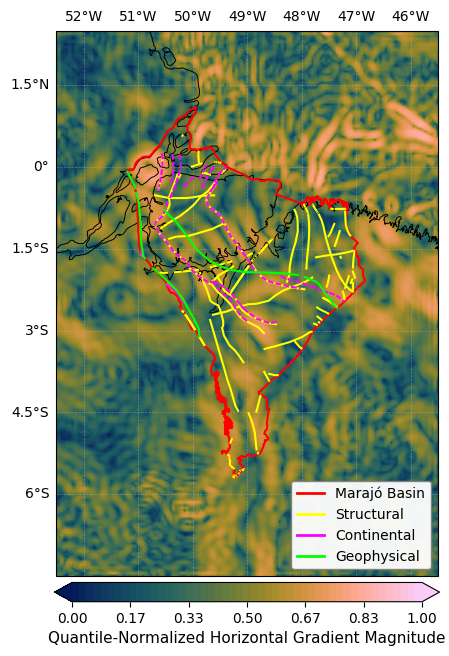

In [20]:
fig = plt.figure(figsize=(8,7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([LON.min(), LON.max(), LAT.min(), LAT.max()],crs=ccrs.PlateCarree())

vmin = np.nanpercentile(QHGM,2)
vmax = np.nanpercentile(QHGM,98)
levels = np.linspace(0,1,50)

cf = ax.contourf(LON,LAT,QHGM,levels=levels,cmap=cm.batlow,extend="both",transform=ccrs.PlateCarree())

marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=10)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Structural"].plot(ax=ax,color="yellow",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Continental"].plot(ax=ax,color="magenta",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Geophysical"].plot(ax=ax,color="lime",linewidth=1.5,zorder=14)

ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False

ticks = np.linspace(0,1,7)
cbar = plt.colorbar(cf,ax=ax,orientation="horizontal",pad=0.01,shrink=0.50,ticks=ticks)
cbar.ax.set_xticklabels([f"{value:.2f}" for value in ticks])
cbar.set_label("Quantile-Normalized Horizontal Gradient Magnitude",fontsize=11)

legend_handles = [Line2D([0],[0],color="red",linewidth=2.0,label="Marajó Basin"),
    Line2D([0],[0],color="yellow",linewidth=2.0,label="Structural"),
    Line2D([0],[0],color="magenta",linewidth=2.0,label="Continental"),
    Line2D([0],[0],color="lime",linewidth=2.0,label="Geophysical"),]

ax.legend(handles=legend_handles,loc="lower right",
          frameon=True,framealpha=0.95,facecolor="white",
          edgecolor="gray",fontsize=10)

plt.tight_layout()
plt.savefig("results/qhgm.png",dpi=300,bbox_inches="tight")
plt.show()

In [21]:
eps = 1e-15
q = 75

heights = np.array([0.0,5.0 * delta,10.0 * delta,20.0 * delta])
QHGM_scales = []
HGM_scales = []

for h in heights:
    print(f"Processing height = {h/1000:.3f} km")
    if h == 0.0:
        field_h = ISO.copy()
    else:
        field_h = filtering.my_upward_continuation(X,Y,ISO,height=h,pad_factor=0.5,pad_mode="reflect",taper=True,flatten=False)

    gx_h = derivative.my_xderiv(X,Y,field_h,n=1,pad_factor=0.5,pad_mode="reflect",taper=True,flatten=False)
    gy_h = derivative.my_yderiv(X,Y,field_h,n=1,pad_factor=0.5,pad_mode="reflect",taper=True,flatten=False)
    H_h = np.sqrt(gx_h**2+gy_h**2)

    lambda_h = np.nanpercentile(H_h,q)

    Q_h = H_h/(H_h+lambda_h+eps)
    HGM_scales.append(H_h)
    QHGM_scales.append(Q_h)

    print(f"  Q75(HGM) = {lambda_h:.6e}")
    print(f"  QHGM min = {np.nanmin(Q_h):.6f}")
    print(f"  QHGM max = {np.nanmax(Q_h):.6f}")

Processing height = 0.000 km
  Q75(HGM) = 6.901171e-04
  QHGM min = 0.001461
  QHGM max = 0.846843
Processing height = 27.804 km
  Q75(HGM) = 2.102598e-04
  QHGM min = 0.000013
  QHGM max = 0.732097
Processing height = 55.607 km
  Q75(HGM) = 1.088109e-04
  QHGM min = 0.000022
  QHGM max = 0.694814
Processing height = 111.214 km
  Q75(HGM) = 4.501328e-05
  QHGM min = 0.000077
  QHGM max = 0.684137


In [ ]:
QHGM_scales = np.asarray(QHGM_scales)
QHGM_mean = np.mean(QHGM_scales,axis=0)

MSQHGM = (QHGM_mean-np.nanmin(QHGM_mean))/(np.nanmax(QHGM_mean)-np.nanmin(QHGM_mean)+eps)

print()
print("MS-QHGM shape:", MSQHGM.shape)
print(f"MS-QHGM min  = {np.nanmin(MSQHGM):.6f}")
print(f"MS-QHGM max  = {np.nanmax(MSQHGM):.6f}")
print(f"MS-QHGM mean = {np.nanmean(MSQHGM):.6f}")
print(f"MS-QHGM std  = {np.nanstd(MSQHGM):.6f}")

In [23]:
QHGM_scales_array = np.stack(QHGM_scales,axis=0)
print("QHGM scales shape:", QHGM_scales_array.shape)

for i, h in enumerate(heights):
    print(f"h = {h/1000:8.3f} km | "
        f"min = {np.nanmin(QHGM_scales_array[i]):.6f} | "
        f"max = {np.nanmax(QHGM_scales_array[i]):.6f} | "
        f"Q75 = {np.nanpercentile(QHGM_scales_array[i],75):.6f}")

QHGM_mean = np.nanmean(QHGM_scales_array,axis=0)

print("Raw multiscale mean:")
print(f"min  = {np.nanmin(QHGM_mean):.6f}")
print(f"max  = {np.nanmax(QHGM_mean):.6f}")
print(f"mean = {np.nanmean(QHGM_mean):.6f}")
print(f"std  = {np.nanstd(QHGM_mean):.6f}")

qmin = np.nanmin(QHGM_mean)
qmax = np.nanmax(QHGM_mean)

MSQHGM = (QHGM_mean-qmin)/(qmax-qmin+1e-15)

print("Final MS-QHGM:")
print("shape:", MSQHGM.shape)
print(f"min  = {np.nanmin(MSQHGM):.6f}")
print(f"max  = {np.nanmax(MSQHGM):.6f}")
print(f"mean = {np.nanmean(MSQHGM):.6f}")
print(f"std  = {np.nanstd(MSQHGM):.6f}")

QHGM scales shape: (4, 201, 141)
h =    0.000 km | min = 0.001461 | max = 0.846843 | Q75 = 0.500000
h =   27.804 km | min = 0.000013 | max = 0.732097 | Q75 = 0.500000
h =   55.607 km | min = 0.000022 | max = 0.694814 | Q75 = 0.500000
h =  111.214 km | min = 0.000077 | max = 0.684137 | Q75 = 0.500000
Raw multiscale mean:
min  = 0.000431
max  = 0.688330
mean = 0.390234
std  = 0.117375
Final MS-QHGM:
shape: (201, 141)
min  = 0.000000
max  = 1.000000
mean = 0.566657
std  = 0.170629


In [24]:
assert np.nanmin(QHGM_scales_array) >= 0.0
assert np.nanmax(QHGM_scales_array) < 1.0
assert np.nanmin(QHGM_mean) >= 0.0
assert np.isclose(np.nanmin(MSQHGM),0.0,atol=1e-10)
assert np.isclose(np.nanmax(MSQHGM),1.0,atol=1e-10)
print("All MS-QHGM consistency checks passed.")

All MS-QHGM consistency checks passed.


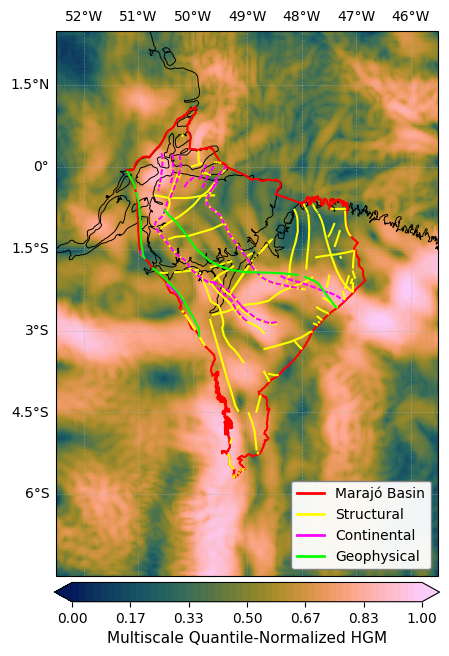

In [25]:
fig = plt.figure(figsize=(8,7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([LON.min(), LON.max(), LAT.min(), LAT.max()],crs=ccrs.PlateCarree())

vmin = np.nanpercentile(MSQHGM,2)
vmax = np.nanpercentile(MSQHGM,98)
levels = np.linspace(0,1,50)

cf = ax.contourf(LON,LAT,MSQHGM,levels=levels,cmap=cm.batlow,extend="both",transform=ccrs.PlateCarree())

marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=10)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Structural"].plot(ax=ax,color="yellow",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Continental"].plot(ax=ax,color="magenta",linewidth=1.5,zorder=14)
estrutural_marajo[estrutural_marajo["SOURCE"]=="Geophysical"].plot(ax=ax,color="lime",linewidth=1.5,zorder=14)

ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False

ticks = np.linspace(0,1,7)
cbar = plt.colorbar(cf,ax=ax,orientation="horizontal",pad=0.01,shrink=0.50,ticks=ticks)
cbar.ax.set_xticklabels([f"{value:.2f}" for value in ticks])
cbar.set_label("Multiscale Quantile-Normalized HGM",fontsize=11)

legend_handles = [Line2D([0],[0],color="red",linewidth=2.0,label="Marajó Basin"),
    Line2D([0],[0],color="yellow",linewidth=2.0,label="Structural"),
    Line2D([0],[0],color="magenta",linewidth=2.0,label="Continental"),
    Line2D([0],[0],color="lime",linewidth=2.0,label="Geophysical"),]

ax.legend(handles=legend_handles,loc="lower right",
          frameon=True,framealpha=0.95,facecolor="white",
          edgecolor="gray",fontsize=10)

plt.tight_layout()
plt.savefig("results/ms_qhgm.png",dpi=300,bbox_inches="tight")
plt.show()

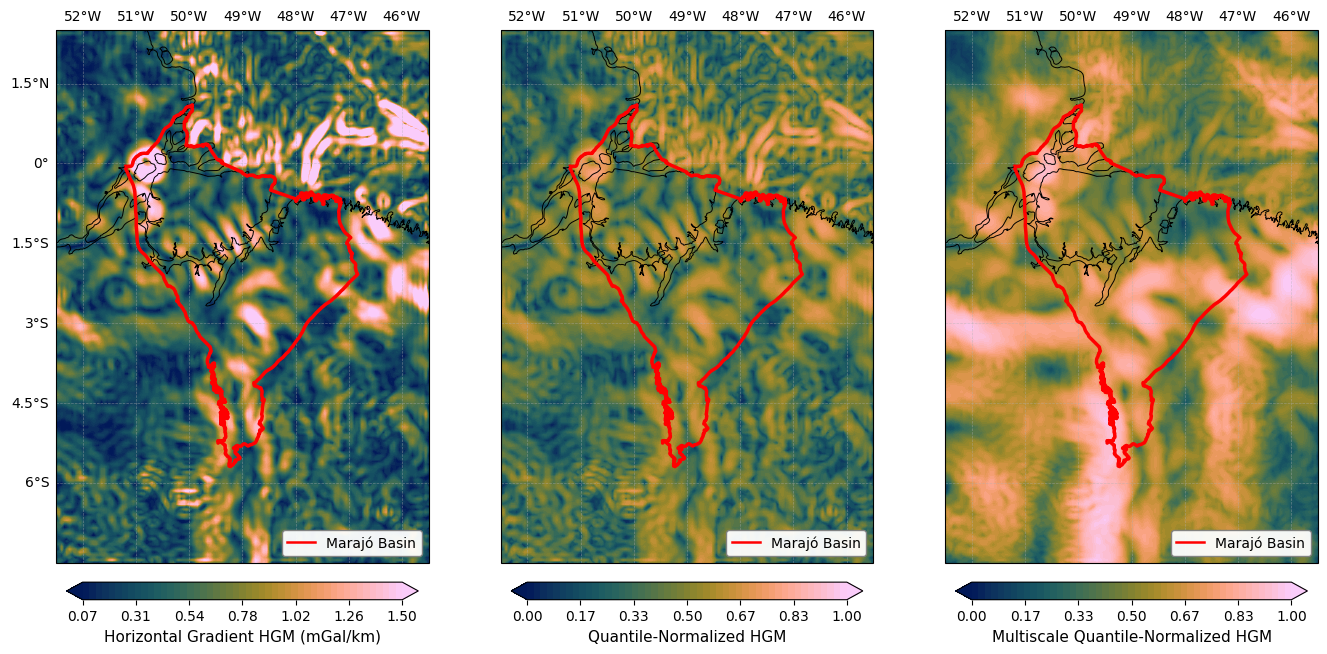

In [26]:
fig, axes = plt.subplots(1, 3,figsize=(14, 7),subplot_kw={"projection": ccrs.PlateCarree()})
extent = [LON.min(),LON.max(),LAT.min(),LAT.max()]
cmap = cm.batlow

ax = axes[0]
ax.set_extent(extent,crs=ccrs.PlateCarree())
vmin_hgm = np.nanpercentile(HGM_km, 2)
vmax_hgm = np.nanpercentile(HGM_km, 98)
levels_hgm = np.linspace(vmin_hgm,vmax_hgm,50)
cf1 = ax.contourf(LON,LAT,HGM_km,levels=levels_hgm,cmap=cmap,extend="both",transform=ccrs.PlateCarree())
marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=2.5,transform=ccrs.PlateCarree(),zorder=10)
ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False
ticks_hgm = np.linspace(vmin_hgm,vmax_hgm,7)
cbar1 = fig.colorbar(cf1,ax=ax,orientation="horizontal",pad=0.03,shrink=0.80,ticks=ticks_hgm)
cbar1.ax.set_xticklabels([f"{value:.2f}" for value in ticks_hgm])
cbar1.set_label("Horizontal Gradient HGM (mGal/km)",fontsize=11)
legend_handles = [Line2D([0], [0],color="red",linewidth=1.8,label="Marajó Basin")]
axes[0].legend(handles=legend_handles,loc="lower right",frameon=True,framealpha=0.95,facecolor="white",edgecolor="gray",fontsize=10)

ax = axes[1]
ax.set_extent(extent,crs=ccrs.PlateCarree())
vmin_norm = 0.0
vmax_norm = 1.0
levels_norm = np.linspace(vmin_norm,vmax_norm,50)
cf2 = ax.contourf(LON,LAT,QHGM,levels=levels_norm,cmap=cmap,extend="both",transform=ccrs.PlateCarree())
marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=2.5,transform=ccrs.PlateCarree(),zorder=10)
ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = False
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False
ticks_norm = np.linspace(0.0,1.0,7)
cbar2 = fig.colorbar(cf2,ax=ax,orientation="horizontal",pad=0.03,shrink=0.80,ticks=ticks_norm)
cbar2.ax.set_xticklabels([f"{value:.2f}" for value in ticks_norm])
cbar2.set_label("Quantile-Normalized HGM",fontsize=11)
legend_handles = [Line2D([0], [0],color="red",linewidth=1.8,label="Marajó Basin")]
axes[1].legend(handles=legend_handles,loc="lower right",frameon=True,framealpha=0.95,facecolor="white",edgecolor="gray",fontsize=10)

ax = axes[2]
ax.set_extent(extent,crs=ccrs.PlateCarree())
cf3 = ax.contourf(LON,LAT,MSQHGM,levels=levels_norm,cmap=cmap,extend="both",transform=ccrs.PlateCarree())
marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=2.5,transform=ccrs.PlateCarree(),zorder=10)
ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = False
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False
cbar3 = fig.colorbar(cf3,ax=ax,orientation="horizontal",pad=0.03,shrink=0.80,ticks=ticks_norm)
cbar3.ax.set_xticklabels([f"{value:.2f}" for value in ticks_norm])
cbar3.set_label("Multiscale Quantile-Normalized HGM",fontsize=11)
legend_handles = [Line2D([0], [0],color="red",linewidth=1.8,label="Marajó Basin")]
axes[2].legend(handles=legend_handles,loc="lower right",frameon=True,framealpha=0.95,facecolor="white",edgecolor="gray",fontsize=10)

plt.tight_layout()
plt.savefig("results/hgm_qhgm_msqhgm.png",dpi=300,bbox_inches="tight")
plt.show()

In [27]:
eps = 1e-15

def normalize01(a):
    a = np.asarray(a, dtype=float)
    amin = np.nanmin(a)
    amax = np.nanmax(a)
    return ((a-amin)/(amax-amin+eps))

def otsu_threshold(data, nbins=256):  
    '''
    Automatic Otsu threshold computed only from the
    filter-response distribution.
    '''
    values = np.asarray(data, dtype=float)
    values = values[np.isfinite(values)]
    hist, bin_edges = np.histogram(values,bins=nbins,range=(0.0, 1.0))    
    hist = hist.astype(float)    
    probability = hist / np.sum(hist)
    bin_centers = 0.5*(bin_edges[:-1]+bin_edges[1:])
    omega = np.cumsum(probability)    
    mu = np.cumsum(probability * bin_centers)    
    mu_total = mu[-1]    
    sigma_b2 = ((mu_total*omega-mu)**2/(omega*(1.0-omega)+eps))
    idx = np.nanargmax(sigma_b2)    
    return bin_centers[idx]

def detect_edge_ridges(response,border=4,nbins=256):
    # Normalize response
    R = normalize01(response)
    # Automatic Otsu threshold
    threshold = otsu_threshold(R,nbins=nbins)
    # Local maxima along x
    maxima_x = np.zeros_like(R,dtype=bool)    
    maxima_x[:, 1:-1] = ((R[:, 1:-1] >= R[:, :-2]) & (R[:, 1:-1] >  R[:, 2:]))
    # Local maxima along y    
    maxima_y = np.zeros_like(R,dtype=bool)    
    maxima_y[1:-1, :] = ((R[1:-1, :] >= R[:-2, :]) & (R[1:-1, :] >  R[2:, :]))
    # Candidate ridge = maximum in either direction
    ridge_candidates = (maxima_x | maxima_y)  
    # Threshold candidates
    ridges = (ridge_candidates & (R >= threshold))
    # Remove outer four grid cells  
    if border > 0:        
        ridges[:border, :] = False
        ridges[-border:, :] = False
        ridges[:, :border] = False
        ridges[:, -border:] = False    
    return R, threshold, ridges

In [28]:
HGM_norm, threshold_hgm, edges_hgm = detect_edge_ridges(HGM,border=4,nbins=256)
QHGM_norm, threshold_qhgm, edges_qhgm = detect_edge_ridges(QHGM,border=4,nbins=256)
MSQHGM_norm, threshold_msqhgm, edges_msqhgm = detect_edge_ridges(MSQHGM,border=4,nbins=256)

print("Automatic Otsu thresholds:")
print(f"HGM     = {threshold_hgm:.4f}")
print(f"QHGM    = {threshold_qhgm:.4f}")
print(f"MS-QHGM = {threshold_msqhgm:.4f}")

print("Detected ridge pixels:")
print(f"HGM     = {np.sum(edges_hgm)}")
print(f"QHGM    = {np.sum(edges_qhgm)}")
print(f"MS-QHGM = {np.sum(edges_msqhgm)}")

Automatic Otsu thresholds:
HGM     = 0.1816
QHGM    = 0.4551
MS-QHGM = 0.5645
Detected ridge pixels:
HGM     = 2798
QHGM    = 5292
MS-QHGM = 3860


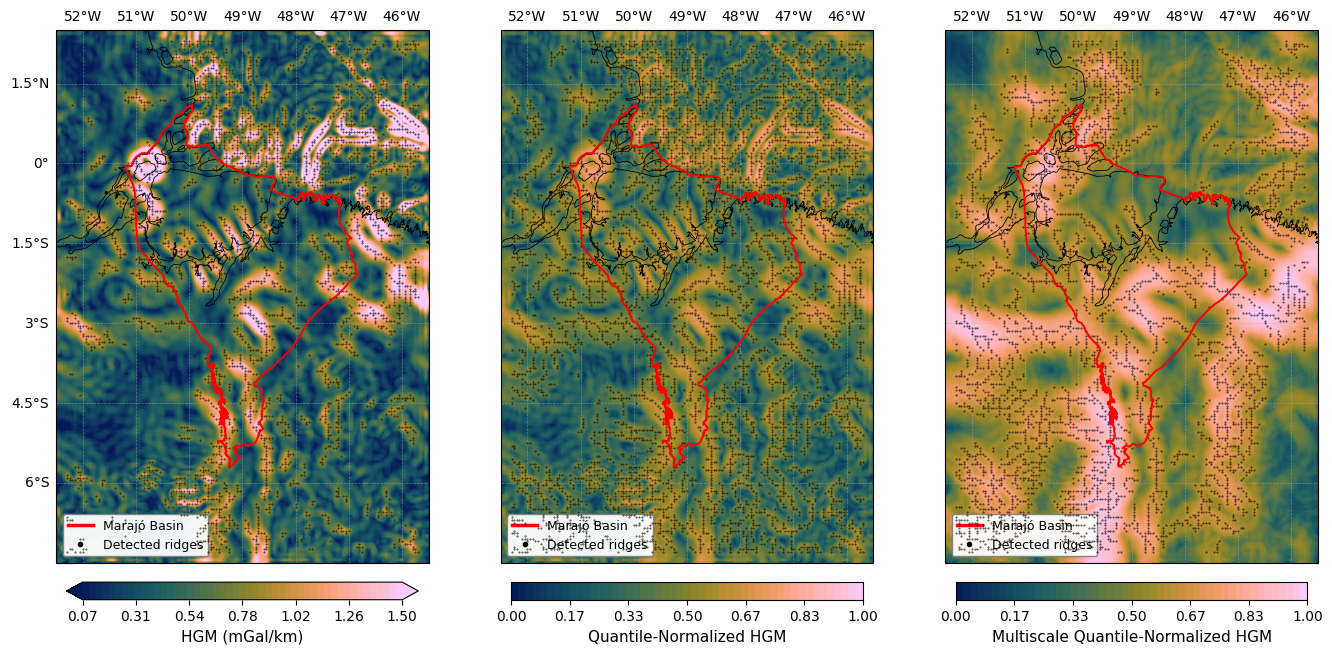

In [29]:
fig,axes = plt.subplots(1,3,figsize=(14,7),subplot_kw={"projection":ccrs.PlateCarree()})

extent = [LON.min(),LON.max(),LAT.min(),LAT.max()]
cmap = cm.batlow
responses = [HGM_km,QHGM,MSQHGM]
edges = [edges_hgm,edges_qhgm,edges_msqhgm]

labels = ["HGM (mGal/km)","Quantile-Normalized HGM","Multiscale Quantile-Normalized HGM"]

for i,ax in enumerate(axes):
    ax.set_extent(extent,crs=ccrs.PlateCarree())
    if i == 0:
        vmin = np.nanpercentile(HGM_km,2)
        vmax = np.nanpercentile(HGM_km,98)
    else:
        vmin = 0.0
        vmax = 1.0
    levels = np.linspace(vmin,vmax,50)
    cf = ax.contourf(LON,LAT,responses[i],levels=levels,cmap=cmap,extend="both" if i == 0 else "neither",transform=ccrs.PlateCarree())
    ax.scatter(LON[edges[i]],LAT[edges[i]],s=0.8,c="black",marker=".",alpha=0.75,transform=ccrs.PlateCarree(),zorder=12)
    marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=1.4,transform=ccrs.PlateCarree(),zorder=13)
    ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.6,zorder=10)
    gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
    gl.top_labels = True
    gl.bottom_labels = False
    gl.right_labels = False
    gl.left_labels = True if i == 0 else False
    gl.x_inline = False
    gl.y_inline = False
    ticks = np.linspace(vmin,vmax,7)
    cbar = fig.colorbar(cf,ax=ax,orientation="horizontal",pad=0.03,shrink=0.80,ticks=ticks)
    cbar.ax.set_xticklabels([f"{value:.2f}" for value in ticks])
    cbar.set_label(labels[i],fontsize=11)

legend_handles = [Line2D([0],[0],color="red",linewidth=2.5,label="Marajó Basin"),
                  Line2D([0],[0],marker=".",color="black",linestyle="None",markersize=6,label="Detected ridges")]
axes[0].legend(handles=legend_handles,loc="lower left",frameon=True,framealpha=0.95,facecolor="white",edgecolor="gray",fontsize=9)
axes[1].legend(handles=legend_handles,loc="lower left",frameon=True,framealpha=0.95,facecolor="white",edgecolor="gray",fontsize=9)
axes[2].legend(handles=legend_handles,loc="lower left",frameon=True,framealpha=0.95,facecolor="white",edgecolor="gray",fontsize=9)

plt.tight_layout()
plt.savefig("results/hgm_qhgm_msqhgm_detected_edges.png",dpi=300,bbox_inches="tight")
plt.show()

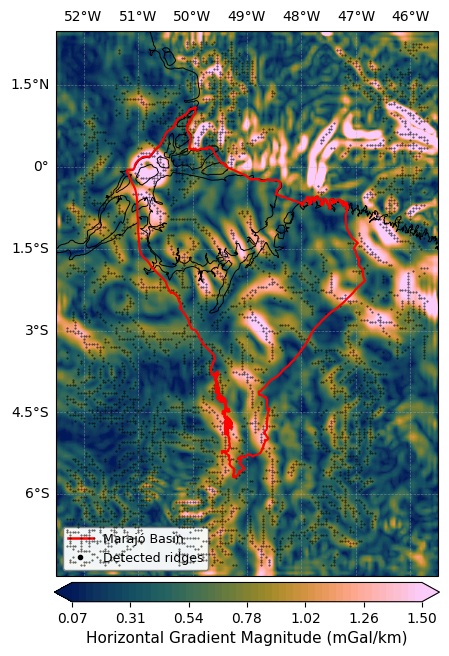

In [30]:
fig = plt.figure(figsize=(8,7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([LON.min(),LON.max(),LAT.min(),LAT.max()],crs=ccrs.PlateCarree())

vmin = np.nanpercentile(HGM_km,2)
vmax = np.nanpercentile(HGM_km,98)
levels = np.linspace(vmin,vmax,50)

cf = ax.contourf(LON,LAT,HGM_km,levels=levels,cmap=cm.batlow,extend="both",transform=ccrs.PlateCarree())

ax.scatter(LON[edges_msqhgm],LAT[edges_msqhgm],s=0.8,c="black",marker=".",alpha=0.75,transform=ccrs.PlateCarree(),zorder=12)
#ax.scatter(LON[edges_hgm],LAT[edges_hgm],s=2.0,c="black",marker=".",transform=ccrs.PlateCarree(),zorder=12)

marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=13)
ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)

gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False

ticks = np.linspace(vmin,vmax,7)

cbar = plt.colorbar(cf,ax=ax,orientation="horizontal",pad=0.01,shrink=0.50,ticks=ticks)
cbar.ax.set_xticklabels([f"{value:.2f}" for value in ticks])
cbar.set_label("Horizontal Gradient Magnitude (mGal/km)",fontsize=11)

legend_handles = [Line2D([0],[0],color="red",linewidth=1.8,label="Marajó Basin"),Line2D([0],[0],marker=".",color="black",linestyle="None",markersize=6,label="Detected ridges")]

ax.legend(handles=legend_handles,loc="lower left",frameon=True,framealpha=0.95,facecolor="white",edgecolor="gray",fontsize=9)

plt.tight_layout()
plt.savefig("results/hgm_detected_edges.png",dpi=300,bbox_inches="tight")
plt.show()

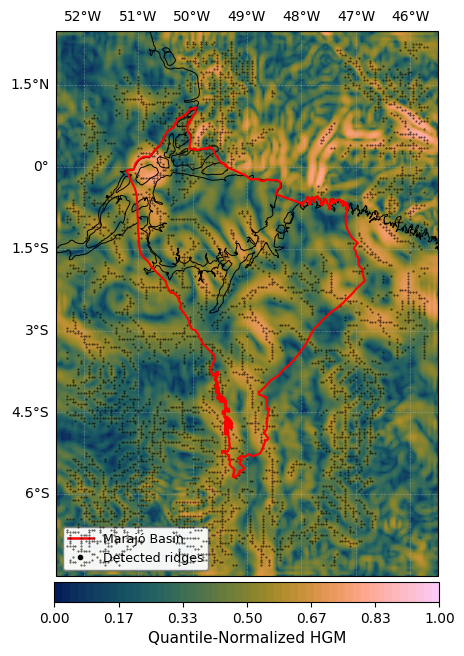

In [31]:
fig = plt.figure(figsize=(8,7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([LON.min(),LON.max(),LAT.min(),LAT.max()],crs=ccrs.PlateCarree())

vmin = 0.0
vmax = 1.0
levels = np.linspace(vmin,vmax,50)

cf = ax.contourf(LON,LAT,QHGM,levels=levels,cmap=cm.batlow,transform=ccrs.PlateCarree())

ax.scatter(LON[edges_msqhgm],LAT[edges_msqhgm],s=0.8,c="black",marker=".",alpha=0.75,transform=ccrs.PlateCarree(),zorder=12)
#ax.scatter(LON[edges_qhgm],LAT[edges_qhgm],s=2.0,c="black",marker=".",transform=ccrs.PlateCarree(),zorder=12)

marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=13)
ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)

gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False

ticks = np.linspace(vmin,vmax,7)

cbar = plt.colorbar(cf,ax=ax,orientation="horizontal",pad=0.01,shrink=0.50,ticks=ticks)
cbar.ax.set_xticklabels([f"{value:.2f}" for value in ticks])
cbar.set_label("Quantile-Normalized HGM",fontsize=11)

legend_handles = [Line2D([0],[0],color="red",linewidth=1.8,label="Marajó Basin"),Line2D([0],[0],marker=".",color="black",linestyle="None",markersize=6,label="Detected ridges")]
ax.legend(handles=legend_handles,loc="lower left",frameon=True,framealpha=0.95,facecolor="white",edgecolor="gray",fontsize=9)

plt.tight_layout()
plt.savefig("results/qhgm_detected_edges.png",dpi=300,bbox_inches="tight")
plt.show()

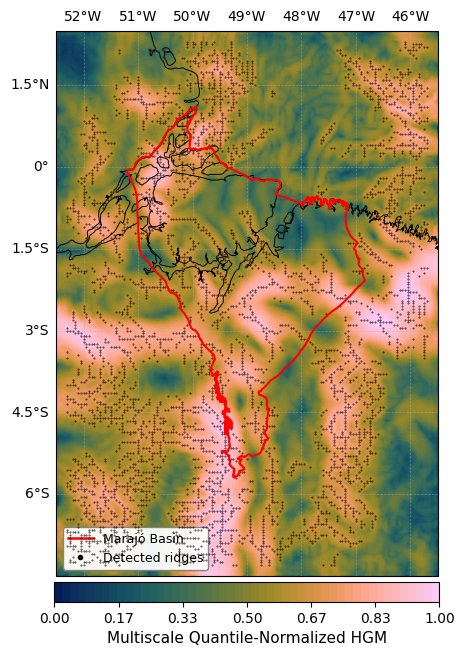

In [32]:
fig = plt.figure(figsize=(8,7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([LON.min(),LON.max(),LAT.min(),LAT.max()],crs=ccrs.PlateCarree())

vmin = 0.0
vmax = 1.0
levels = np.linspace(vmin,vmax,50)

cf = ax.contourf(LON,LAT,MSQHGM,levels=levels,cmap=cm.batlow,transform=ccrs.PlateCarree())

ax.scatter(LON[edges_msqhgm],LAT[edges_msqhgm],s=0.8,c="black",marker=".",alpha=0.75,transform=ccrs.PlateCarree(),zorder=12)
#ax.scatter(LON[edges_msqhgm],LAT[edges_msqhgm],s=2.0,c="black",marker=".",transform=ccrs.PlateCarree(),zorder=12)

marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=13)
ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)

gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False

ticks = np.linspace(vmin,vmax,7)

cbar = plt.colorbar(cf,ax=ax,orientation="horizontal",pad=0.01,shrink=0.50,ticks=ticks)
cbar.ax.set_xticklabels([f"{value:.2f}" for value in ticks])
cbar.set_label("Multiscale Quantile-Normalized HGM",fontsize=11)

legend_handles = [Line2D([0],[0],color="red",linewidth=1.8,label="Marajó Basin"),Line2D([0],[0],marker=".",color="black",linestyle="None",markersize=6,label="Detected ridges")]
#ax.legend(handles=legend_handles,loc="upper left",bbox_to_anchor=(1.01,1.00),frameon=True,framealpha=0.95,facecolor="white",edgecolor="gray",fontsize=9)
ax.legend(handles=legend_handles,loc="lower left",frameon=True,framealpha=0.95,facecolor="white",edgecolor="gray",fontsize=9)

plt.tight_layout()
plt.savefig("results/msqhgm_detected_edges.png",dpi=300,bbox_inches="tight")
plt.show()

### Creating a mask inside Marajó basin using shapely

In [33]:
from shapely import contains_xy

basin_geom = marajo.geometry.union_all()

mask_marajo = contains_xy(basin_geom,LON,LAT)

edges_hgm_marajo = edges_hgm & mask_marajo
edges_qhgm_marajo = edges_qhgm & mask_marajo
edges_msqhgm_marajo = edges_msqhgm & mask_marajo

print("Grid points inside Marajó Basin:",np.sum(mask_marajo))
print()
print("Detected ridge pixels inside Marajó Basin:")
print(f"HGM     = {np.sum(edges_hgm_marajo)}")
print(f"QHGM    = {np.sum(edges_qhgm_marajo)}")
print(f"MS-QHGM = {np.sum(edges_msqhgm_marajo)}")

print()
print("Fraction of detected ridges inside the basin:")
print(f"HGM     = {100*np.sum(edges_hgm_marajo)/np.sum(edges_hgm):.2f}%")
print(f"QHGM    = {100*np.sum(edges_qhgm_marajo)/np.sum(edges_qhgm):.2f}%")
print(f"MS-QHGM = {100*np.sum(edges_msqhgm_marajo)/np.sum(edges_msqhgm):.2f}%")

Grid points inside Marajó Basin: 5239

Detected ridge pixels inside Marajó Basin:
HGM     = 620
QHGM    = 1028
MS-QHGM = 664

Fraction of detected ridges inside the basin:
HGM     = 22.16%
QHGM    = 19.43%
MS-QHGM = 17.20%


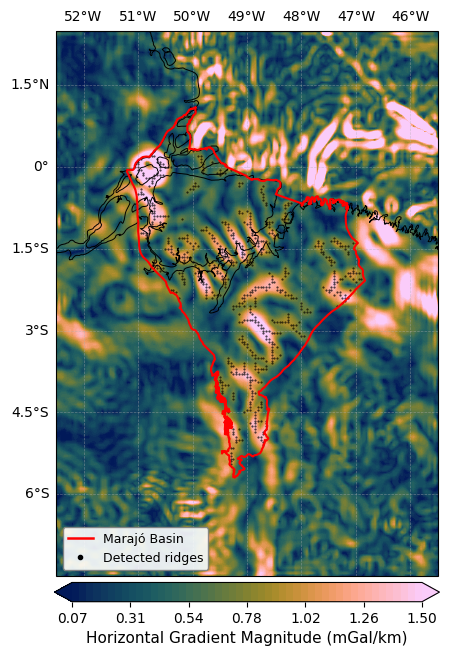

In [34]:
fig = plt.figure(figsize=(8,7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([LON.min(),LON.max(),LAT.min(),LAT.max()],crs=ccrs.PlateCarree())

vmin = np.nanpercentile(HGM_km,2)
vmax = np.nanpercentile(HGM_km,98)
levels = np.linspace(vmin,vmax,50)

cf = ax.contourf(LON,LAT,HGM_km,levels=levels,cmap=cm.batlow,extend="both",transform=ccrs.PlateCarree())
ax.scatter(LON[edges_hgm_marajo],LAT[edges_hgm_marajo],s=1.0,c="black",marker=".",alpha=0.80,transform=ccrs.PlateCarree(),zorder=12)
marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=13)
ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)

gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False

ticks = np.linspace(vmin,vmax,7)
cbar = plt.colorbar(cf,ax=ax,orientation="horizontal",pad=0.01,shrink=0.50,ticks=ticks)
cbar.ax.set_xticklabels([f"{value:.2f}" for value in ticks])
cbar.set_label("Horizontal Gradient Magnitude (mGal/km)",fontsize=11)

legend_handles = [Line2D([0],[0],color="red",linewidth=1.8,label="Marajó Basin"),Line2D([0],[0],marker=".",color="black",linestyle="None",markersize=6,label="Detected ridges")]
ax.legend(handles=legend_handles,loc="lower left",frameon=True,framealpha=0.90,facecolor="white",edgecolor="gray",fontsize=9)

plt.tight_layout()
plt.savefig("results/hgm_edges_marajo_basin.png",dpi=300,bbox_inches="tight")
plt.show()

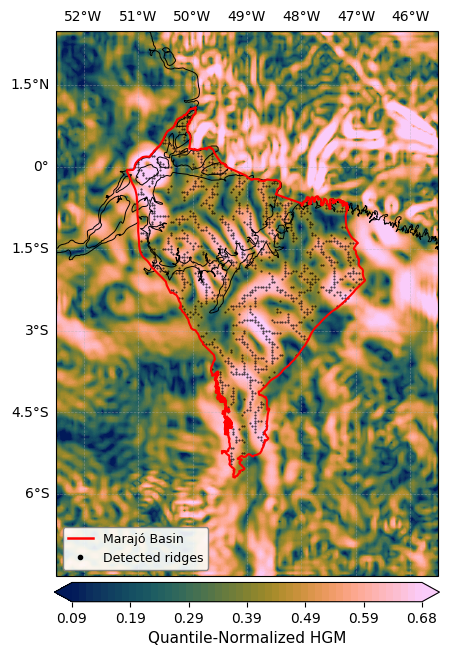

In [35]:
fig = plt.figure(figsize=(8,7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([LON.min(),LON.max(),LAT.min(),LAT.max()],crs=ccrs.PlateCarree())

vmin = np.nanpercentile(QHGM,2)
vmax = np.nanpercentile(QHGM,98)
levels = np.linspace(vmin,vmax,50)

cf = ax.contourf(LON,LAT,QHGM,levels=levels,cmap=cm.batlow,extend="both",transform=ccrs.PlateCarree())
ax.scatter(LON[edges_qhgm_marajo],LAT[edges_qhgm_marajo],s=1.0,c="black",marker=".",alpha=0.80,transform=ccrs.PlateCarree(),zorder=12)
marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=13)
ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)

gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False

ticks = np.linspace(vmin,vmax,7)
cbar = plt.colorbar(cf,ax=ax,orientation="horizontal",pad=0.01,shrink=0.50,ticks=ticks)
cbar.ax.set_xticklabels([f"{value:.2f}" for value in ticks])
cbar.set_label("Quantile-Normalized HGM",fontsize=11)

legend_handles = [Line2D([0],[0],color="red",linewidth=1.8,label="Marajó Basin"),Line2D([0],[0],marker=".",color="black",linestyle="None",markersize=6,label="Detected ridges")]
ax.legend(handles=legend_handles,loc="lower left",frameon=True,framealpha=0.90,facecolor="white",edgecolor="gray",fontsize=9)

plt.tight_layout()
plt.savefig("results/qhgm_edges_marajo_basin.png",dpi=300,bbox_inches="tight")
plt.show()

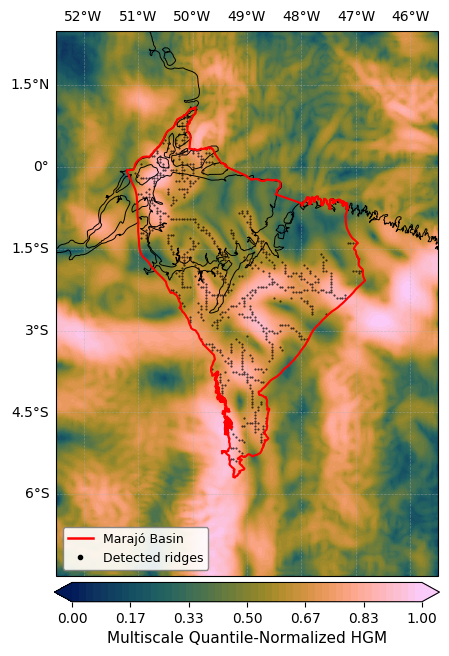

In [36]:
fig = plt.figure(figsize=(8,7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([LON.min(),LON.max(),LAT.min(),LAT.max()],crs=ccrs.PlateCarree())

vmin = 0.0
vmax = 1.0
levels = np.linspace(vmin,vmax,50)

cf = ax.contourf(LON,LAT,MSQHGM,levels=levels,cmap=cm.batlow,extend="both",transform=ccrs.PlateCarree())

ax.scatter(LON[edges_msqhgm_marajo],LAT[edges_msqhgm_marajo],s=1.0,c="black",marker=".",alpha=0.80,transform=ccrs.PlateCarree(),zorder=12)

marajo.boundary.plot(ax=ax,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=13)
ax.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)

gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False
gl.x_inline = False
gl.y_inline = False

ticks = np.linspace(vmin,vmax,7)

cbar = plt.colorbar(cf,ax=ax,orientation="horizontal",pad=0.01,shrink=0.50,ticks=ticks)
cbar.ax.set_xticklabels([f"{value:.2f}" for value in ticks])
cbar.set_label("Multiscale Quantile-Normalized HGM",fontsize=11)

legend_handles = [Line2D([0],[0],color="red",linewidth=1.8,label="Marajó Basin"),Line2D([0],[0],marker=".",color="black",linestyle="None",markersize=6,label="Detected ridges")]

ax.legend(handles=legend_handles,loc="lower left",frameon=True,framealpha=0.90,facecolor="white",edgecolor="gray",fontsize=9)

plt.tight_layout()
plt.savefig("results/msqhgm_edges_marajo_basin.png",dpi=300,bbox_inches="tight")
plt.show()

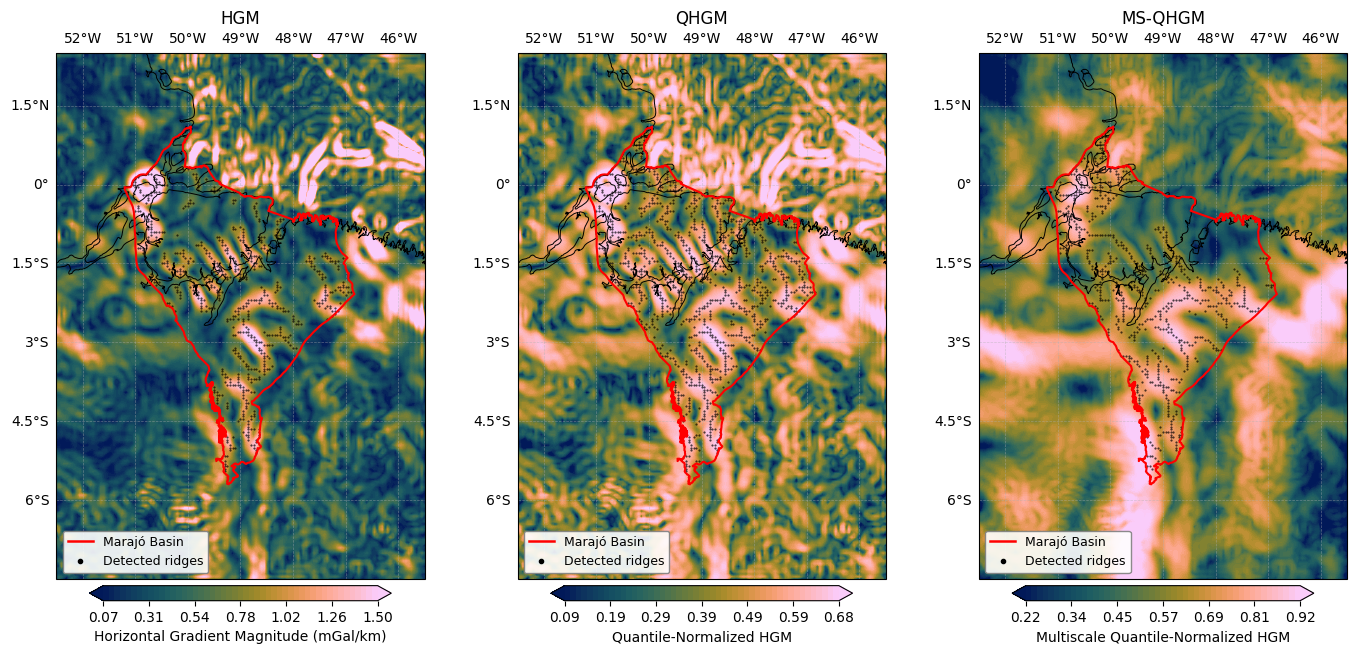

In [37]:
fig = plt.figure(figsize=(14,7))

ax1 = fig.add_subplot(1,3,1,projection=ccrs.PlateCarree())
ax1.set_extent([LON.min(),LON.max(),LAT.min(),LAT.max()],crs=ccrs.PlateCarree())
vmin1 = np.nanpercentile(HGM_km,2)
vmax1 = np.nanpercentile(HGM_km,98)
levels1 = np.linspace(vmin1,vmax1,50)
cf1 = ax1.contourf(LON,LAT,HGM_km,levels=levels1,cmap=cm.batlow,extend="both",transform=ccrs.PlateCarree())
ax1.scatter(LON[edges_hgm_marajo],LAT[edges_hgm_marajo],s=1.0,c="black",marker=".",alpha=0.80,transform=ccrs.PlateCarree(),zorder=12)
marajo.boundary.plot(ax=ax1,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=13)
ax1.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)
gl1 = ax1.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl1.top_labels = True
gl1.bottom_labels = False
gl1.left_labels = True
gl1.right_labels = False
gl1.x_inline = False
gl1.y_inline = False
ax1.set_title("HGM",fontsize=12)
ticks1 = np.linspace(vmin1,vmax1,7)
cbar1 = plt.colorbar(cf1,ax=ax1,orientation="horizontal",pad=0.01,shrink=0.75,ticks=ticks1)
cbar1.ax.set_xticklabels([f"{value:.2f}" for value in ticks1])
cbar1.set_label("Horizontal Gradient Magnitude (mGal/km)",fontsize=10)
legend_handles1 = [Line2D([0],[0],color="red",linewidth=1.8,label="Marajó Basin"),Line2D([0],[0],marker=".",color="black",linestyle="None",markersize=6,label="Detected ridges")]
ax1.legend(handles=legend_handles1,loc="lower left",frameon=True,framealpha=0.90,facecolor="white",edgecolor="gray",fontsize=9)

ax2 = fig.add_subplot(1,3,2,projection=ccrs.PlateCarree())
ax2.set_extent([LON.min(),LON.max(),LAT.min(),LAT.max()],crs=ccrs.PlateCarree())
vmin2 = np.nanpercentile(QHGM,2)
vmax2 = np.nanpercentile(QHGM,98)
levels2 = np.linspace(vmin2,vmax2,50)
cf2 = ax2.contourf(LON,LAT,QHGM,levels=levels2,cmap=cm.batlow,extend="both",transform=ccrs.PlateCarree())
ax2.scatter(LON[edges_qhgm_marajo],LAT[edges_qhgm_marajo],s=1.0,c="black",marker=".",alpha=0.80,transform=ccrs.PlateCarree(),zorder=12)
marajo.boundary.plot(ax=ax2,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=13)
ax2.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)
gl2 = ax2.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl2.top_labels = True
gl2.bottom_labels = False
gl2.left_labels = True
gl2.right_labels = False
gl2.x_inline = False
gl2.y_inline = False
ax2.set_title("QHGM",fontsize=12)
ticks2 = np.linspace(vmin2,vmax2,7)
cbar2 = plt.colorbar(cf2,ax=ax2,orientation="horizontal",pad=0.01,shrink=0.75,ticks=ticks2)
cbar2.ax.set_xticklabels([f"{value:.2f}" for value in ticks2])
cbar2.set_label("Quantile-Normalized HGM",fontsize=10)
legend_handles2 = [Line2D([0],[0],color="red",linewidth=1.8,label="Marajó Basin"),Line2D([0],[0],marker=".",color="black",linestyle="None",markersize=6,label="Detected ridges")]
ax2.legend(handles=legend_handles2,loc="lower left",frameon=True,framealpha=0.90,facecolor="white",edgecolor="gray",fontsize=9)

ax3 = fig.add_subplot(1,3,3,projection=ccrs.PlateCarree())
ax3.set_extent([LON.min(),LON.max(),LAT.min(),LAT.max()],crs=ccrs.PlateCarree())
vmin3 = np.nanpercentile(MSQHGM,2)
vmax3 = np.nanpercentile(MSQHGM,98)
levels3 = np.linspace(vmin3,vmax3,50)
cf3 = ax3.contourf(LON,LAT,MSQHGM,levels=levels3,cmap=cm.batlow,extend="both",transform=ccrs.PlateCarree())
ax3.scatter(LON[edges_msqhgm_marajo],LAT[edges_msqhgm_marajo],s=1.0,c="black",marker=".",alpha=0.80,transform=ccrs.PlateCarree(),zorder=12)
marajo.boundary.plot(ax=ax3,edgecolor="red",linewidth=1.5,transform=ccrs.PlateCarree(),zorder=13)
ax3.add_feature(cfeature.COASTLINE.with_scale("10m"),linewidth=0.7,zorder=8)
gl3 = ax3.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=0.5,linestyle="--",alpha=0.5)
gl3.top_labels = True
gl3.bottom_labels = False
gl3.left_labels = True
gl3.right_labels = False
gl3.x_inline = False
gl3.y_inline = False
ax3.set_title("MS-QHGM",fontsize=12)
ticks3 = np.linspace(vmin3,vmax3,7)
cbar3 = plt.colorbar(cf3,ax=ax3,orientation="horizontal",pad=0.01,shrink=0.75,ticks=ticks3)
cbar3.ax.set_xticklabels([f"{value:.2f}" for value in ticks3])
cbar3.set_label("Multiscale Quantile-Normalized HGM",fontsize=10)
legend_handles3 = [Line2D([0],[0],color="red",linewidth=1.8,label="Marajó Basin"),Line2D([0],[0],marker=".",color="black",linestyle="None",markersize=6,label="Detected ridges")]
ax3.legend(handles=legend_handles3,loc="lower left",frameon=True,framealpha=0.90,facecolor="white",edgecolor="gray",fontsize=9)

plt.tight_layout()
plt.savefig("results/hgm_qhgm_msqhgm_edges_marajo_basin.png",dpi=300,bbox_inches="tight")
plt.show()